# Gravity Corrections
----------------

Today's goals:
* Finish up discussing the corrections applied to gravity data
* Work through an example

# TODAY
**NOTICE THE SIGNS OF THE CORRECTIONS**

## Review: Components of an observed value:
$$ g_{total} = g_{sphere} + \Delta g_{latitude} + \Delta g_{free-air} + \Delta g_{eotvos} + \Delta g_{iso} + \Delta g_{drift} + \Delta g_{terrain} + \Delta g_{anomaly}$$

1) $g_{sphere}$ Reference spheroid
1) $\Delta g_{latitude} \rightarrow$ Reference Spheroid $\rightarrow$ Lattitude correction
1) $\Delta g_{free-air} \rightarrow$ Effect due to vertical gradient $\rightarrow$ Free Air correction
1) $\Delta g_{eotvos} \rightarrow$ Moving platform $\rightarrow$ Eotvos correction
1) $\Delta g_{iso} \rightarrow$ Isostatic effects $\rightarrow$ Isostatic correction
1) $\Delta g_{drift} \rightarrow$ Tidal and instrument drift $\rightarrow$ Drift correction
1) $\Delta g_{terrain} \rightarrow$ Field due to background mass above sea level $\rightarrow$ Bouguer and Terrain correction
1) $\Delta g_{anomaly} \rightarrow$ Local geology $\rightarrow$ What we want.

## Latitude Correction
* Removing the reference field from the spheroid
* International Gravity Formula (IGRF) (spheroid)
    * **closed form expression for if you use an absolute gravimeter**:
    $ g_{ref} = g_{sphere} + \Delta g_{lat} = g_e \frac{1 + k \sin^2\phi}{\sqrt{1 - \eta^2 \sin^2\phi}} $
        * $g_e = 978.03267714$ Gal
        * $k = 0.00193185138639$
        * $\eta^2 = 0.0069437999013$
        * $\phi$ - latitude
    * Or approximate:
      $g = g_e (1 + \alpha sin^2\phi + \beta \sin^4\phi)$

    *   **formula for if you use a relative gravimeter:**  $$\Delta g_{\text{Lat}} = 0.001626 \cdot \sin(\phi) \cos(\phi) \cdot \Delta y \quad (\text{mGal}) \quad $$
        * $\phi$: The reference latitude of your base station or starting profile point (e.g., $45^\circ$ for Golden, CO) .
        * $\Delta y$: The distance north (positive) or south (negative) from the reference latitude point, measured in meters   

$$ g_{total} - g_{sphere} - \Delta g_{lat} - ... $$

## Free Air Correction
![false](resources/8-fa-example.png)

* We just removed the ellipsoid so now we reference elevation to the ellipsoid: 
* **The correction for a point with elevation h is therefore given by:**
    $$ \Delta g_{fa} = -2 \frac{h}{R}g_0 \approx -0.3086 \frac{mGal}{m} h$$
    * i.e., the free air gradient is -0.3086 mGal/m
* NOTE: For relative gravity measurements, the background field is implicitly removed (missing).
    * The main concern is the false anomaly produced by elevation differences.
    * A correction based on this difference $\Delta h$ relative to a base station will suffice
    * But... $h$ is used customarily.

$$ g_{total} - g_{sphere} - \Delta g_{lat} - \Delta g_{free-air}... $$

## Drift Corrections

![corr](resources/drift_correction.png)

Correction method:
* approximate the drift curve by line segments, making a function for the gravity at the base station as a function of time.
    $$ g_{interp, base}(t) = \frac{g_2 - g_1}{t_2 - t_1}(t - t_1) + g_1 $$

$$ g_{total} - g_{sphere} - \Delta g_{lat} - \Delta g_{free-air} - \Delta g_{drift}... $$

### Eotvos Correction
* Correct for the alteration to the measurement due to the ship’s motion.
    * Differences in speed relative to spin of the earth
* Necessary for marine and airborne surveys.
* Need to have data for the speed and heading of the platform: 
* **Eotvos correction is given by:**
    $$\Delta g_{eotvos} = -2(\omega v \sin \lambda \cos \phi  + \frac{v^2}{R})$$
    * $v$: Speed of the platform (ship or aircraft) relative to the ground.
    * $\lambda$: Heading angle of the vessel (measured clockwise from True North)
    * $\phi$: Latitude
    * $\omega$: Earth's angular rotation speed ($\approx 7.292 \times 10^{-5} \text{ rad/s}$).
    * $R$: Earth's radius ($\approx 6,371 \text{ km}$).

$$ g_{total} - g_{sphere} - \Delta g_{lat} - \Delta g_{free-air} - \Delta g_{drift} - \Delta g_{eotvos}... $$

### Let's return to the isostatic correction

Isostatic Effect
* The fact that geoid does not correlate with excess or deficient  mass distributions can only mean the following: 
    1) The excess mass is compensated by mass deficient at depth
    1) while deficient mass is compensated by excess mass below. 
* This is called isostatic compensation.
* The mechanism can be best understood by the model of a lighter material floating on top of a heavier “fluid”. 

Two models:
1) Airy’s model: varying depth extent
2) Pratt’s model: laterally varying density

![prattairy](resources/Comparison-of-the-Pratt-and-Airy-models-for-isostatic-compensation-m-marks-the.png)

### The correction method
* Only for large surveys that are on the regional scale.
* Less definitive (we don’t know the distribution of the causative mass)
* Correction can be done effectively using Airy’s model, 
    1) calculate the shape (depth extent) of the compensating mass based on surface topography 
    2) integrate the gravity effect by numerical integration.
* for small scale survey, isostatic effect can be lumped together with the “regional” field to be separated in the interpretation stage.


* Airy’s model: columns of equal mass
* derive the crustal thickness of Airy’s model
    $$d_m = h \frac{\rho_{top}}{\Delta \rho} + d_s$$
    * $h$ topographic height above sea level with density $\rho_{\text{top}}$ (or $\rho_c$).
    * $d_s=30$ km (standard crustal thickness at sea level)
    * $\rho_{c}\approx2.67$ g/cc
    * $\Delta \rho=\rho_m - \rho_c \approx 0.35$ g/cc (mantle density minus continental crust density)
* calculate the gravity effect due to the volume that deviates from the “standard” thickness below the shore line
    $$ \Delta g_{iso} = ... \text{ from a computer}$$

  Super complicated... 3D Integration: Calculating the vertical gravitational attraction ($g_z$) of a continuously varying 3D surface geometry requires solving Newton's law over a volume integral:$$\Delta g_{\text{iso}} = \gamma \iiint_V \frac{(-\Delta \rho) \cdot z}{(x^2 + y^2 + z^2)^{3/2}} \, dx \, dy \, dz$$
Surface topography $h(x,y)$ changes continuously across terrain so calculating this 3D integral analytically by hand is nearly impossible. Instead, geophysics software discretizes the calculated root map into thousands of 3D prisms or polygons and uses numerical integration to compute $\Delta g_{\text{iso}}$ at every station

![iso](resources/9-airy-calc.png)

$$ g_{total} - g_{sphere} - \Delta g_{lat} - \Delta g_{free-air} - \Delta g_{drift} - \Delta g_{eotvos} - \Delta g_{iso}... $$

## Back to Bouguer and Terrain Corrections
Bouguer and terrain corrections are traditionally discussed as two separate steps of data reduction,
I've previously said you need information about an area to apply a Bouguer correction, but you can actually solve for it. This is because terrain and Bouguer anomalies are related....


**In the process of removing gravitational effect of the background density below the topo surface down to the sea level, you will determine both the Bouguer and Terrain corrections**
* The objective is to subtract the field produced by the background density and obtain the field due to the anomolous density: $\Delta \rho = \rho - \rho_b$.
* Look at the image below.
    * In the first panel, we have the measured gravity (corrected up to this point except for the Bouguer and Terrain) and the real geology that caused this response
    * In the next panel, we have the predicted gravitational response given a constant density (a likely density for the area) with the current terrain (complicated to predict, but done simply with a computer program -  numerical integration of the DEM).
    * In the final panel, the response drops to zero off of the anomaly. **To do this, in the prior step, the program iteratively sampled a variety of densities of $\rho_b$  until the background was centered on zero in the final panel**

**THIS FINAL $\rho_b$ IS THE DENSITY OF OUR SLAB**



![terr](resources/9-terrain_corr.png)

The field due to the background density is given by an integration over the entire volume of $\rho_B$
* Another way of saying that this is all done in two parts: 
    1) Effect of a slab with thickness equal to the station elevation:
        * simple analytical solution available:$\rightarrow$ Bouguer Correction
    2) effect of excess and deficient mass introduced by the terrain:
        * numerical integration required:     $\rightarrow$         Terrain Correction
      
> **Rule of thumb:** If your corrected gravity map still looks like a topographic map, your density is wrong.

### Breaking the calculation into two pieces

Computing the pull of *all* the rock under a bumpy landscape at once is hard. So we split it into an easy part and a leftover part:

| Piece | What it represents | How it's calculated | Name |
|---|---|---|---|
| 1 | A flat, uniform layer of rock as thick as the station is high above sea level | One simple formula | **Bouguer correction** |
| 2 | Everything the flat layer gets wrong: hills sticking up above you and valleys dipping below you | Computer (numerical integration over the DEM) | **Terrain correction** |

Add the two together and you have the full effect of the background rock.

![terr](resources/9-terr-label.png)

$$\Delta g_{slab} + \Delta g_{T} = \Delta g_B$$
![parts](resources/9-terr-parts.png)

### Bouguer correction:
* This is the gravitational effect of a slab with thickness h and infinite horizontal extent.
    $$\Delta g_{slab} = 2 \pi \gamma \rho_B h $$
* Assuming a density of $\rho_B=2.67$ g/cc gives:
    $$\Delta g_{slab} = 0.1119\frac{mGal}{m} h $$
* Usually, the density is unknown, and it needs to be estimated by directly sampling or by using numerical techniques.

### Terrain Correction
This part calculates the effect of what’s left by the simple Bouguer correction.
* Essentially models the gravity response of this:
![terr](resources/9-terr-only.png)
* As I've said before, don't do it yourself
* Make a computer do it for you...
  $$ \Delta g_{T} = F(\text{observation locations, terrain, density})$$

**note** Used to be done by hand using Hammer charts:
![hammer](resources/9-hammer.png)

### Summary

1. Measured gravity includes the pull of ordinary rock between you and sea level. We want to remove it.
2. **Bouguer correction:** remove a flat slab of rock as thick as your elevation (about 0.11 mGal per meter at 2.67 g/cc).
3. **Terrain correction:** fix the slab's errors caused by nearby hills and valleys. It is almost always positive, so it gets added back.
4. **Density:** if you don't know it, try different values until the corrected data stops looking like the topography.
5. What's left is the anomaly caused by the geology you're after.

$$ g_{total} - g_{sphere} - \Delta g_{lat} - \Delta g_{free-air} - \Delta g_{drift} - \Delta g_{eotvos} - \Delta g_{iso} - \Delta g_{B} = g_{anomaly}$$

## Corrections example, on a profile

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read in some data

Let's plot and read in some data

In [2]:
data = pd.read_csv('resources/profile_data.csv')
data

,Station Label,Northing (m),Elevation (m),Time (h),obs (mGal)
0,Base,NaN,NaN,0.00,980081.07
1,0,0.0,1812.02,0.15,979724.81
2,1,50.0,1812.03,0.28,979724.96
3,2,100.0,1812.03,0.44,979725.13
4,3,150.0,1812.03,0.56,979725.28
5,4,200.0,1812.03,0.70,979725.44
6,5,250.0,1812.02,0.85,979725.62
7,6,300.0,1812.00,0.98,979725.79
8,7,350.0,1811.93,1.10,979725.97
9,Base,NaN,NaN,1.20,980081.94


First, let's get the indices of the base stations, and the indices of everywhere else.

In [3]:
base_inds = np.where(data['Station Label'] == "Base")[0]
station_inds = np.where(data['Station Label'] != "Base")[0]
base_inds

array([ 0,  9, 20, 32, 45])

Now let's plot the observed value at each station, according to its northing location

Text(0.5, 1.0, '2D Profile of Raw Gravity Readings')

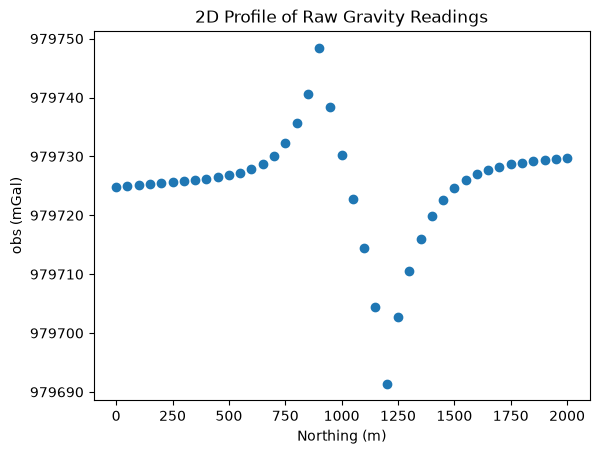

In [4]:
plt.scatter(data['Northing (m)'][station_inds], data['obs (mGal)'][station_inds])
plt.xlabel('Northing (m)')
plt.ylabel('obs (mGal)')
plt.title('2D Profile of Raw Gravity Readings')

# Drift-Correction

Text(0.5, 1.0, 'Raw gravity readings vs. time')

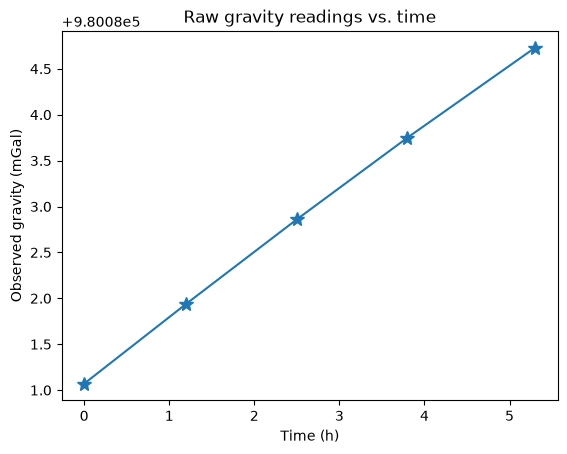

In [5]:
plt.plot(data['Time (h)'][base_inds], data['obs (mGal)'][base_inds], marker='*', markersize=10)
plt.xlabel('Time (h)')
plt.ylabel('Observed gravity (mGal)')
plt.title('Raw gravity readings vs. time')

We can do some nice stuff with python here to make this easy!
So what do we want?
* Need a function that describes the base station as a function of time...
* Remove that variability from the observed data.

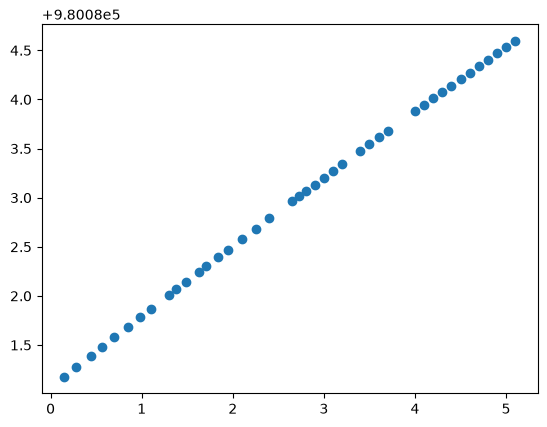

In [6]:
# part one sounds like an interpolation....
# Want to interpolate the values of the base station at times of the observations!
times = data['Time (h)']
obs = data['obs (mGal)']

g_drift = np.interp(times[station_inds], times[base_inds], obs[base_inds])

plt.scatter(times[station_inds], g_drift)

Text(0.5, 0, 'Time (h)')

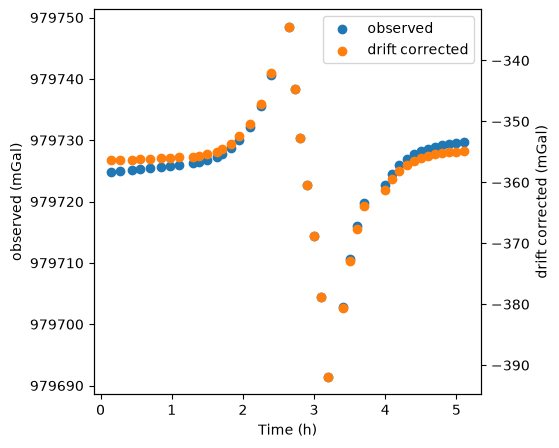

In [7]:
fig, ax1 = plt.subplots(figsize=(5, 5))
ax2 = ax1.twinx()

p1 = ax1.scatter(times[station_inds], obs[station_inds], color='C0', label='observed')
p2 = ax2.scatter(times[station_inds], obs[station_inds]-g_drift, color='C1', label='drift corrected')

ax1.legend(handles=[p1, p2])
ax1.set_ylabel('observed (mGal)')
ax2.set_ylabel('drift corrected (mGal)')
ax1.set_xlabel('Time (h)')

Now the other ones are pretty formulaic
# Free air

$$ \Delta g_{FA} = -0.3086 (mGal/m) * h $$

Text(0, 0.5, 'Elevations (m)')

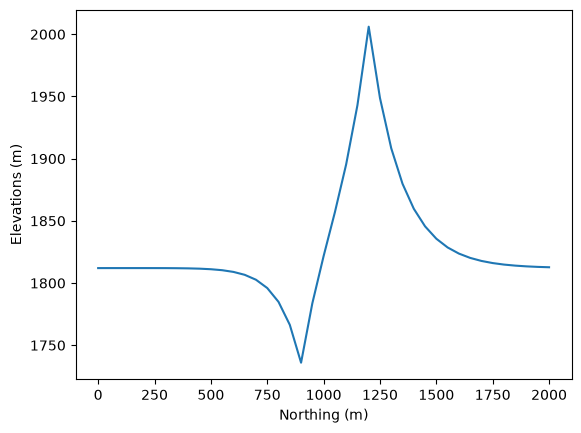

In [8]:
# Do the free air correction
profile = data['Northing (m)'][station_inds]
height = data['Elevation (m)'][station_inds]
plt.plot(profile, height)
plt.xlabel('Northing (m)')
plt.ylabel('Elevations (m)')

# don't come at me for this wild elevation profile...

Text(0, 0.5, 'obs (mGal)')

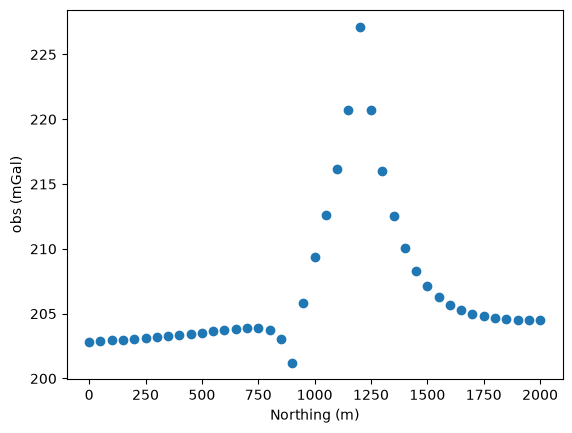

In [9]:
g_obs = data['obs (mGal)'][station_inds]

g_fa = -0.3086 * height


plt.scatter(profile, g_obs - g_drift - g_fa)
plt.xlabel('Northing (m)')
plt.ylabel('obs (mGal)')

# Simple Bouguer correction

The simple bouguer correction removes an infinite slab with a thickness $h$ from the data.

$$\Delta g_{Bouguer} = 2 \pi \gamma \rho h$$

I'm going to assume this is continental crust....
So for $\rho = 2.67 g/cc$ this gives:

$$\Delta g_{bouguer} = 0.1119 (mGal/m) * h $$

Text(0, 0.5, 'obs (mGal)')

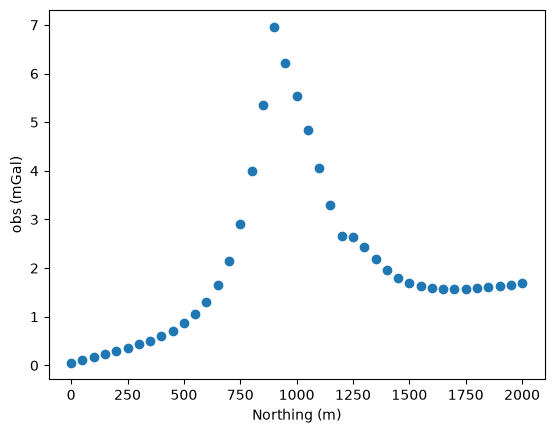

In [10]:
g_bouguer = 0.1119 * height # 2 pi gamma rho * h,  (rho=2.67)


plt.scatter(profile, g_obs - g_drift - g_fa - g_bouguer)
plt.xlabel('Northing (m)')
plt.ylabel('obs (mGal)')

# Latitude correction

The full latitude correction is:

$$ \Delta g_{Lat} = g_e \left( \frac{1 + k \sin^2 \phi}{\sqrt{1-e^2 \sin^2 \phi}} - 1\right)$$

with $g_e = 978032.67714 mGal$, $k =  0.00193185138639$, and $e^2=0.00669437999013$ at latitude $\phi$


However for this data set, we used a relative gravimeter and we are only given the latitude at the relative 0 North of the profile (45$\degree$) and the distance north from each point, thus we will use the approximation:

$$ \Delta g_{Lat} = 0.001626 (mGal/m) * \sin\phi\cos\phi * \Delta y$$

where $\Delta y$ is the difference in northing from the reference latitude point at $\phi$

this data has a reference point of 45$\degree$.... Golden?

**note:** Remember to convert from degrees to radians for numpy!

Text(0, 0.5, 'obs (mGal)')

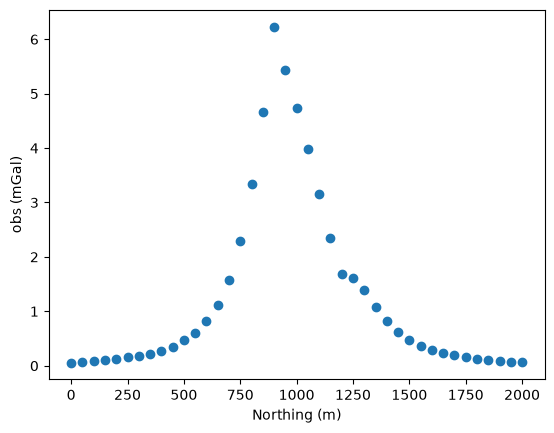

In [11]:
lat = np.pi/180 * 45

g_lat = 0.001626 * np.sin(lat) * np.cos(lat) * profile

plt.scatter(profile, g_obs - g_drift - g_fa - g_bouguer - g_lat)
plt.xlabel('Northing (m)')
plt.ylabel('obs (mGal)')

Text(0, 0.5, 'obs (mGal)')

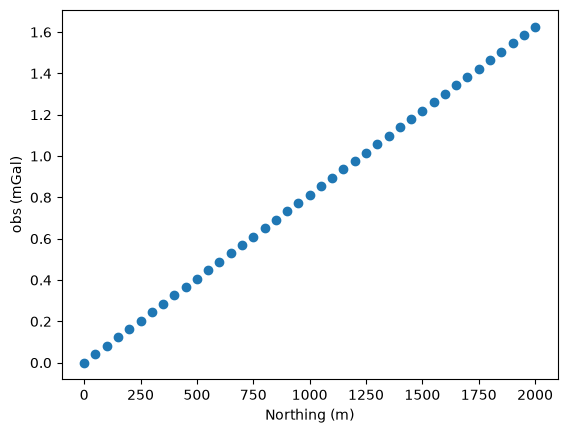

In [12]:
plt.scatter(profile, g_lat)
plt.xlabel('Northing (m)')
plt.ylabel('obs (mGal)')

Text(0, 0.5, 'corrected (mGal)')

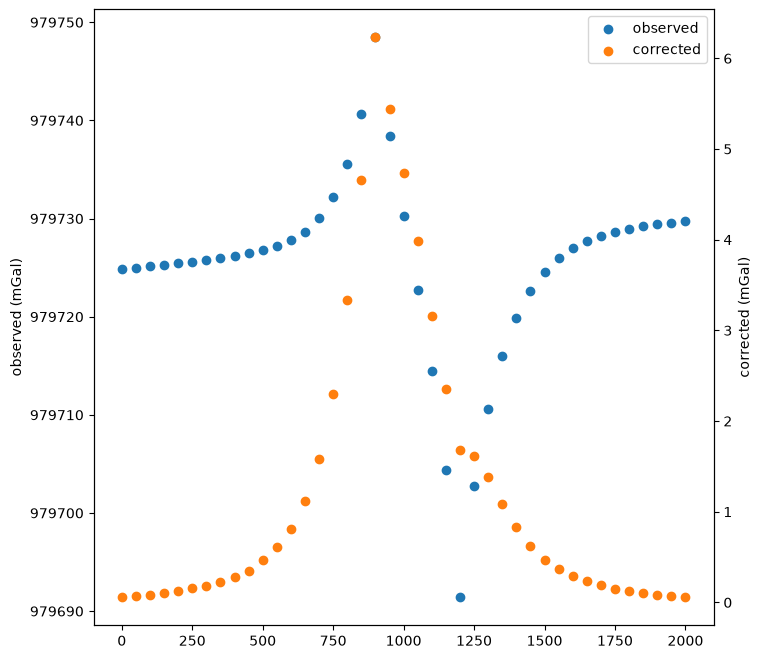

In [13]:

fig, ax1 = plt.subplots(figsize=(8, 8))
ax2 = ax1.twinx()

p1 = ax1.scatter(data['Northing (m)'][station_inds], data['obs (mGal)'][station_inds], label='observed', color='C0')
p2 = ax2.scatter(profile, g_obs - g_drift - g_fa - g_bouguer - g_lat, label='corrected', color='C1')

ax1.legend(handles=[p1, p2])
ax1.set_ylabel('observed (mGal)')
ax2.set_ylabel('corrected (mGal)')

Woooah